# 01 — Exploring the SPI price series

**Goal (Phase 3):** look at the data with our own eyes before building any detector.
What does "normal" look like for each item, which items are volatile vs sticky, where are the
obvious spikes, and does Ramazan show up?

Data: national average weekly prices from `data/mehngai.db` (8 items, 2019-09-05 → today).
This notebook only *reads* the database — it never touches PDFs or CSVs.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from hijridate import Hijri
from matplotlib.colors import LinearSegmentedColormap

from mehngai.config import DATA_DIR, PROJECT_ROOT
from mehngai.store.db import connect, read_prices

FIG_DIR = PROJECT_ROOT / "notebooks" / "figures"
FIG_DIR.mkdir(exist_ok=True)

# Chart style: one accent colour for data, recessive grid/axes, text in neutral inks.
BLUE, ORANGE = "#2a78d6", "#eb6834"         # validated pair (colour-blind safe)
INK, INK_2, GRID, SURFACE, BAND = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb", "#ecebe7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

ITEM_NAMES = {"wheat_flour": "Wheat flour (20 kg)", "sugar": "Sugar (1 kg)", "ghee": "Ghee (1 kg pouch)",
              "tomatoes": "Tomatoes (1 kg)", "onions": "Onions (1 kg)", "potatoes": "Potatoes (1 kg)",
              "chicken": "Chicken (1 kg live)", "eggs": "Eggs (dozen)"}

with connect() as conn:
    prices = read_prices(conn)                               # long: week_date, item_id, price
wide = prices.pivot(index="week_date", columns="item_id", values="price")
events = pd.read_csv(DATA_DIR / "known_events.csv", parse_dates=["start_week", "end_week"])
print(wide.shape, wide.index.min().date(), "→", wide.index.max().date())

(354, 8) 2019-09-05 → 2026-10-08


### Ramazan dates
Ramazan follows the lunar (Hijri) calendar, so it starts ~11 days earlier every year. We convert
1 Ramazan and 1 Shawwal (Eid ul-Fitr) of each Hijri year to Gregorian dates. (Pakistan's moon-sighting
can differ by a day — irrelevant at weekly resolution.)

In [2]:
ramazan = pd.DataFrame([
    {"hijri_year": y,
     "start": pd.Timestamp(Hijri(y, 9, 1).to_gregorian()),
     "eid": pd.Timestamp(Hijri(y, 10, 1).to_gregorian())}
    for y in range(1441, 1449)
])
ramazan = ramazan[(ramazan.eid >= wide.index.min()) & (ramazan.start <= wide.index.max())]
ramazan

,hijri_year,start,eid
0,1441,2020-04-24,2020-05-24
1,1442,2021-04-13,2021-05-13
2,1443,2022-04-02,2022-05-02
3,1444,2023-03-23,2023-04-21
4,1445,2024-03-11,2024-04-10
5,1446,2025-03-01,2025-03-30
6,1447,2026-02-18,2026-03-20


## 1. Price history

Each panel has its own y-axis (prices differ 100×). Grey bands = Ramazan. Orange dots = documented
price shocks from `data/known_events.csv` (found in news coverage).

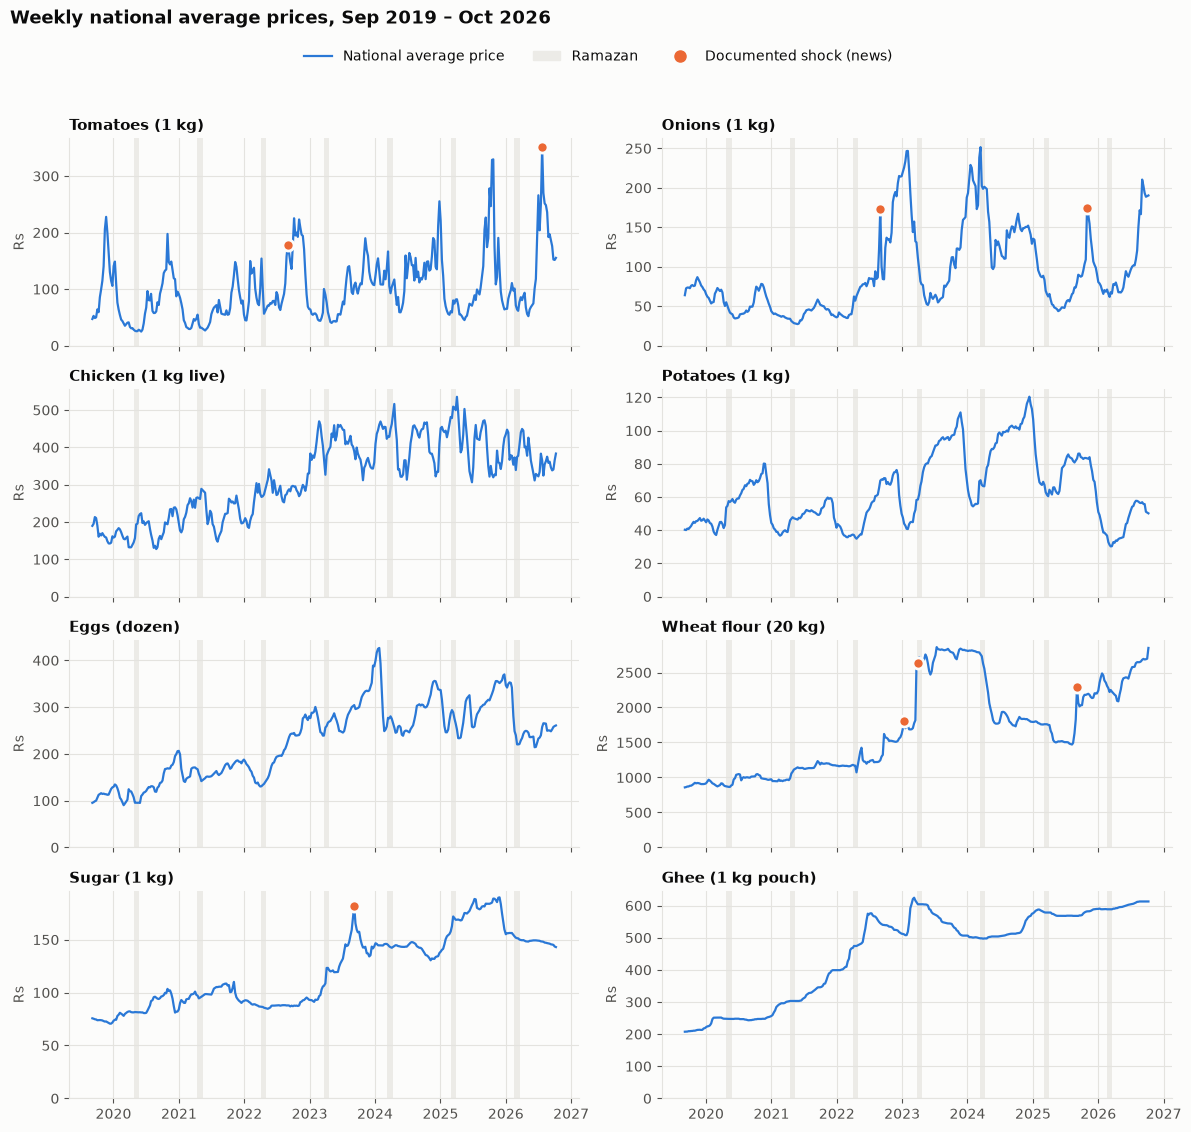

In [3]:
order = ["tomatoes", "onions", "chicken", "potatoes", "eggs", "wheat_flour", "sugar", "ghee"]
fig, axes = plt.subplots(4, 2, figsize=(12, 11), sharex=True)
for ax, item in zip(axes.flat, order):
    for r in ramazan.itertuples():
        ax.axvspan(r.start, r.eid, color=BAND, lw=0, zorder=0)
    ax.plot(wide.index, wide[item], color=BLUE, lw=1.6, zorder=2)
    for e in events[events.item_id == item].itertuples():
        window = wide.loc[e.start_week:e.end_week, item]
        if len(window):
            ax.plot(window.idxmax(), window.max(), "o", ms=8, color=ORANGE,
                    mec=SURFACE, mew=2, zorder=3)
    ax.set_title(ITEM_NAMES[item])
    ax.set_ylabel("Rs")
    ax.set_ylim(bottom=0)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
fig.legend(handles=[Line2D([], [], color=BLUE, lw=1.6, label="National average price"),
                    Patch(color=BAND, label="Ramazan"),
                    Line2D([], [], marker="o", ls="", ms=8, color=ORANGE, label="Documented shock (news)")],
           loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.suptitle("Weekly national average prices, Sep 2019 – Oct 2026", x=0.01, y=1.025, ha="left",
             fontweight="bold", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(FIG_DIR / "01_price_history.png", dpi=120, bbox_inches="tight")
plt.show()

**What we see**
- **Everything roughly doubles to triples** over seven years (general inflation, worst in 2022–23). That's
  why the detector must work on *% changes*, not raw prices.
- **Tomatoes and onions** are spiky: sharp peaks that come back down within weeks (2022 floods, Oct 2025,
  Jul 2026).
- **Wheat flour, sugar, ghee** move in *steps*: long flat stretches, then a jump to a new level that stays
  (flour Mar 2023, sugar Aug–Sep 2023). A step is a different kind of anomaly from a spike.
- **Chicken and eggs** sit in between: a lot of week-to-week noise plus some seasonal swings.

## 2. Volatile vs sticky items

Weekly % change = change vs the previous report. *Median absolute change* = "how much does this item
typically move in a week" — a robust measure that one extreme week can't distort (that's why we use
the median, not the mean). Note: ~5% of steps span a 2–3 week gap (missing PBS reports).

In [4]:
pct = wide.pct_change() * 100
gap_days = wide.index.to_series().diff().dt.days
print("steps by gap length (days):", gap_days.value_counts().sort_index().to_dict())

vol = pd.DataFrame({
    "typical weekly move %": pct.abs().median(),
    "95th pct move %": pct.abs().quantile(0.95),
    "weeks moving >5 %": (pct.abs() > 5).mean() * 100,
    "biggest rise %": pct.max(),
    "biggest fall %": pct.min(),
}).sort_values("typical weekly move %", ascending=False).round(1)
vol.index = vol.index.map(ITEM_NAMES)
vol

steps by gap length (days): {6.0: 12, 7.0: 314, 8.0: 12, 14.0: 13, 21.0: 2}


,typical weekly move %,95th pct move %,weeks moving >5 %,biggest rise %,biggest fall %
item_id,,,,,
Tomatoes (1 kg),12.0,41.9,78.5,125.4,-47.0
Onions (1 kg),4.5,21.6,44.6,59.5,-42.0
Chicken (1 kg live),4.5,15.5,44.4,23.7,-21.3
Potatoes (1 kg),2.1,10.4,21.5,24.8,-18.5
Eggs (dozen),2.1,8.5,18.1,22.0,-28.8
Wheat flour (20 kg),0.7,5.8,6.8,42.3,-12.2
Sugar (1 kg),0.6,4.7,4.0,13.5,-9.3
Ghee (1 kg pouch),0.2,2.3,1.1,8.0,-1.9


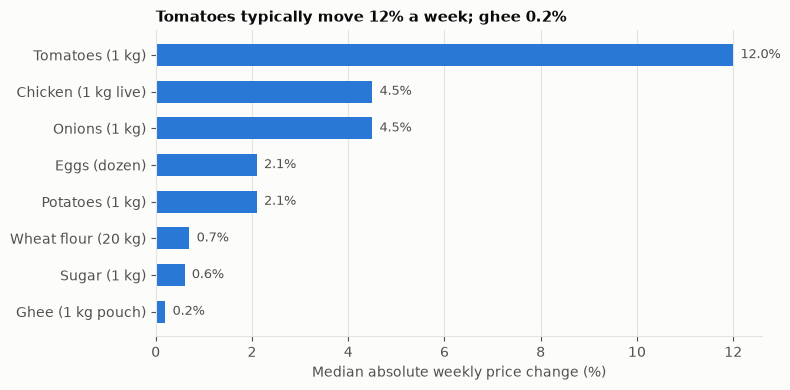

In [5]:
v = vol["typical weekly move %"].sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(v.index, v.values, color=BLUE, height=0.6)
for y, val in enumerate(v.values):
    ax.text(val + 0.15, y, f"{val:.1f}%", va="center", color=INK_2, fontsize=9)
ax.set_xlabel("Median absolute weekly price change (%)")
ax.set_title("Tomatoes typically move 12% a week; ghee 0.2%")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_volatility.png", dpi=120, bbox_inches="tight")
plt.show()

**Takeaway:** a 10% weekly jump is an ordinary week for tomatoes but would be extraordinary for sugar.
One global threshold ("flag anything >X%") can't work for both — that's the core argument for
**per-item statistics** (L1 rolling z-score) over the L0 fixed threshold. Three groups:
- **Volatile:** tomatoes (12%), onions (4.5%), chicken (4.4%)
- **Medium:** potatoes, eggs (~2%)
- **Sticky:** wheat flour, sugar (<1%), ghee (0.2%)

## 3. Shape of weekly changes

Box = middle 50% of weeks, whiskers = 1.5× box width, dots = outlier weeks. Long tails (many far-out dots)
mean "normal" rules based on mean ± standard deviation will be thrown off — another reason for median/MAD.

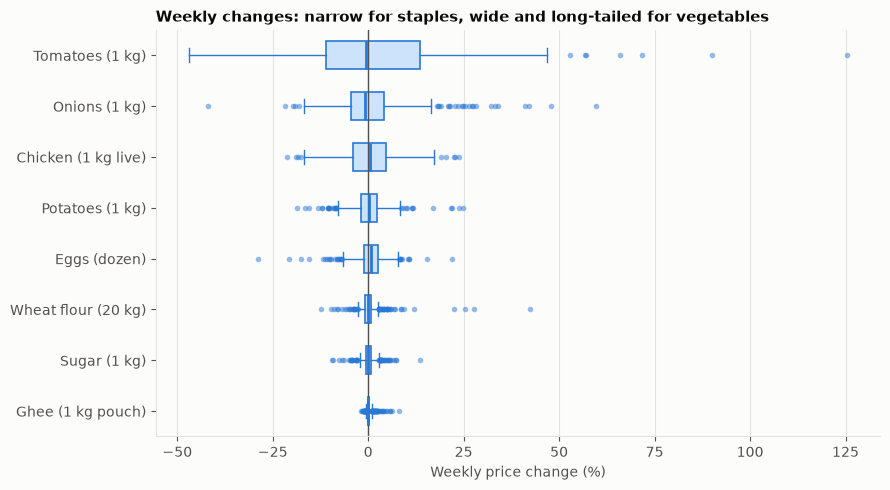

skew (positive = rises are bigger than falls):
item_id
wheat_flour    5.19
ghee           3.12
onions         1.43
tomatoes       1.15
potatoes       0.60
sugar          0.36
chicken        0.14
eggs          -1.11


In [6]:
order_v = vol.index[::-1]                      # least → most volatile, bottom to top
data = [pct[k].dropna().values for k in [next(i for i, n in ITEM_NAMES.items() if n == name) for name in order_v]]
fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot(data, orientation="horizontal", tick_labels=order_v, widths=0.55, patch_artist=True,
           boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE, linewidth=1.2),
           medianprops=dict(color=BLUE, linewidth=2), whiskerprops=dict(color=BLUE),
           capprops=dict(color=BLUE),
           flierprops=dict(marker="o", markersize=4, markerfacecolor=BLUE, markeredgecolor="none", alpha=0.5))
ax.axvline(0, color=INK_2, lw=1)
ax.set_xlabel("Weekly price change (%)")
ax.set_title("Weekly changes: narrow for staples, wide and long-tailed for vegetables")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_change_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

print("skew (positive = rises are bigger than falls):")
print(pct.skew().round(2).sort_values(ascending=False).to_string())

## 4. Does Ramazan show up?

For every week we compute *weeks relative to the start of Ramazan* (−6 … +6), then take the median weekly
% change across the 7 Ramazans in our data, minus the item's normal median change. Red = prices rise faster
than usual in that week, blue = slower. Only 7 Ramazans, so read this as a hint, not proof.

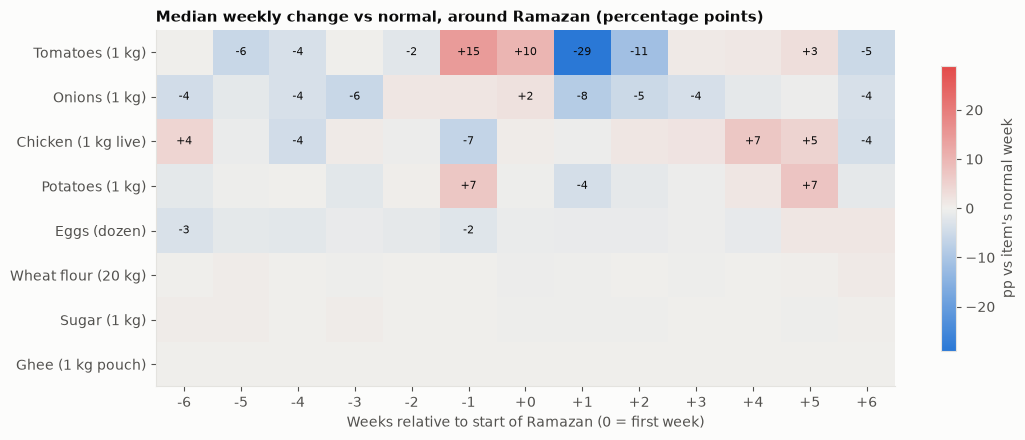

In [7]:
def weeks_from_ramazan(d: pd.Timestamp) -> float:
    diffs = (d - ramazan.start).dt.days
    nearest = diffs.iloc[diffs.abs().argmin()]
    return np.floor(nearest / 7)

rel = pct.copy()
rel["rel_week"] = [weeks_from_ramazan(d) for d in rel.index]
rel = rel[rel.rel_week.between(-6, 6)]
excess = rel.groupby("rel_week")[list(ITEM_NAMES)].median() - pct.median()
excess = excess.T.loc[order]

lim = np.nanmax(np.abs(excess.values))
cmap = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(11, 4.5))
im = ax.imshow(excess.values, cmap=cmap, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(excess.columns)), [f"{int(c):+d}" for c in excess.columns])
ax.set_yticks(range(len(excess.index)), [ITEM_NAMES[i] for i in excess.index])
for (r, c), val in np.ndenumerate(excess.values):
    if abs(val) >= 2:                                        # label only the notable cells
        ax.text(c, r, f"{val:+.0f}", ha="center", va="center", fontsize=8, color=INK)
ax.axvline(-0.5, color=INK, lw=1.2)                         # boundary: week 0 = first week of Ramazan
ax.set_xlabel("Weeks relative to start of Ramazan (0 = first week)")
ax.set_title("Median weekly change vs normal, around Ramazan (percentage points)")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.8)
cb.set_label("pp vs item's normal week")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_ramazan_effect.png", dpi=120, bbox_inches="tight")
plt.show()

**Ramazan findings** (7 Ramazans — a hint, not proof)
- **Tomatoes:** rise ~10–15 pp faster than a normal week in the week *before* and the *first* week of
  Ramazan, then drop sharply in week +1 (−29 pp). A pre-Ramazan demand bump that fades quickly.
- **Chicken:** +5–7 pp around weeks +4/+5, i.e. around **Eid ul-Fitr** (Ramazan lasts ~4 weeks).
- **Onions:** no Ramazan bump; if anything below normal (spring is new-crop season).
- **Wheat flour, sugar, ghee, eggs:** no Ramazan pattern.

**Implication for detection:** without a Ramazan feature, L1/L2 would flag the pre-Ramazan tomato rise
and the Eid chicken rise every year. L3 needs it mainly for those two items.

## 5. Biggest weekly moves (candidates for known events)

The three biggest weekly rises per item. The ones we could match to news coverage are in
`data/known_events.csv` (with a link); the rest are still unexplained — part of Phase 4's
precision check.

In [8]:
rows = []
for item in order:
    for d, v in pct[item].nlargest(3).items():
        matched = events[(events.item_id == item) & (events.start_week <= d) & (events.end_week >= d)]
        rows.append({"item": ITEM_NAMES[item], "week": d.date(), "change %": round(v, 1),
                     "price Rs": round(wide.loc[d, item], 1),
                     "gap days": int(gap_days.loc[d]),
                     "known event": matched.event_id.iloc[0] if len(matched) else ""})
pd.DataFrame(rows)

,item,week,change %,price Rs,gap days,known event
0,Tomatoes (1 kg),2026-07-02,125.4,265.9,14,E08
1,Tomatoes (1 kg),2022-02-03,90.1,149.6,7,
2,Tomatoes (1 kg),2023-03-22,71.8,100.2,6,
3,Onions (1 kg),2025-10-30,59.5,174.1,7,E07
4,Onions (1 kg),2022-09-29,47.8,124.1,7,
5,Onions (1 kg),2022-09-01,42.2,173.7,7,E02
6,Chicken (1 kg live),2020-05-07,23.7,193.6,7,
7,Chicken (1 kg live),2025-07-10,22.6,424.7,7,
8,Chicken (1 kg live),2024-12-26,22.5,409.2,7,
9,Potatoes (1 kg),2020-04-23,24.8,53.7,7,


## Summary — what "normal" looks like (3 items)

| | Onions | Sugar | Wheat flour (20 kg) |
|---|---|---|---|
| **Typical week** | moves ~4.5% | moves ~0.6% | moves ~0.7% |
| **Shape** | yearly cycle: cheap in spring/summer, climbs through autumn/winter | long flat stretches, occasional steps | flat for months, then **steps** to a new level that stays |
| **Obvious spikes** | Aug–Sep 2022 floods (+41% in a week, E02); **+59.5% on 30 Oct 2025** (E07) | Aug–Sep 2023 to Rs 182 (E05); +13.5% on 6 Apr 2023 (inside Ramazan; no news found yet) | **+42% on 22 Mar 2023** to a record Rs 2,586 (E04); 2025 floods +25% (E06) |
| **Big drops** | −42% the week after the Sep 2022 peak | small (≤ 9%) | 2024 post-harvest slide from ~Rs 2,800 to ~Rs 1,500 (gradual) |

**Lessons for Phase 4 (detection)**
1. **Per-item scale is essential** — 10% is a normal tomato week and an extreme sugar week.
2. **Robust stats** — weekly changes are long-tailed (wheat flour skew 5.2), so mean/std would be distorted.
3. **Seasonality exists** for vegetables (yearly cycle) and **Ramazan/Eid** effects for tomatoes and chicken.
4. **Spikes vs steps** — a step (flour, sugar) should be flagged once, then become the new normal; a rolling
   window does this naturally.
5. **Report gaps** — 15 of 353 steps span 2–3 weeks (e.g. flour +27.7% on 12 May 2022 is a 3-week change).
   The detector must not treat a 3-week change as a 1-week change.
6. **Drops matter too** (onions −42%, eggs −29% in Feb 2024) — report them, rank spikes first.

**Known events collected so far:** 8, all with a news source (`data/known_events.csv`). Unexplained big moves
(tomatoes Feb 2022, chicken Dec 2024 / Jul 2025, potatoes Mar 2024, eggs Mar 2020) are candidates to research
in Phase 4.